# Multi-label classification — look at your data first

Most failed projects fail here, not in the model. Before training anything, answer:
1. **How common is each label?** (a rare label is hard to learn and easy to ignore)
2. **How many labels does a typical image have?** (including images with none)
3. **Which labels appear together?** (co-occurrence the model can exploit — or be fooled by)

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/multilabel/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("multilabel", cfg)
print("task:", "multilabel", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: multilabel | data: data/demo/multilabel | outputs: outputs/multilabel_quick


## How the data is organised
An `images/` folder plus `labels.csv`: the first column is the file name, then one **0/1 column per label** (the header gives the label names). The split is random, fixed by `seed`.

## How common is each label?

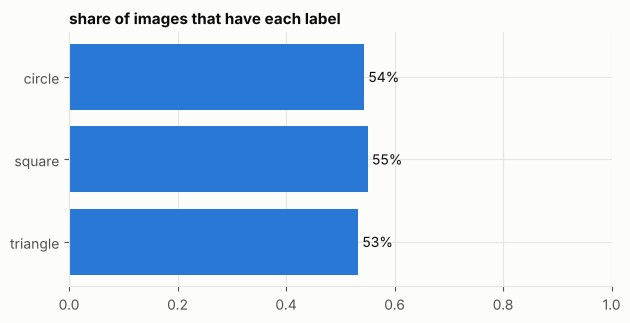

rarest label: triangle (53%) -> consider train.pos_weight=true


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from cvkit.viz import BLUE
from tasks.multilabel.data import build_datasets

ds = build_datasets(cfg)
classes, samples = ds["classes"], ds["samples"]
Y = np.array([t for _, t in samples])                  # (images, labels) of 0/1
freq = Y.mean(0)

fig, ax = plt.subplots(figsize=(7, 0.6 * len(classes) + 1.5))
ax.barh(classes, freq, color=BLUE); ax.invert_yaxis(); ax.set_xlim(0, 1)
for i, f in enumerate(freq):
    ax.text(f, i, f" {f:.0%}", va="center")
ax.set_title("share of images that have each label")
plt.show()
print("rarest label:", classes[int(freq.argmin())], f"({freq.min():.0%}) -> consider train.pos_weight=true")

## Labels per image

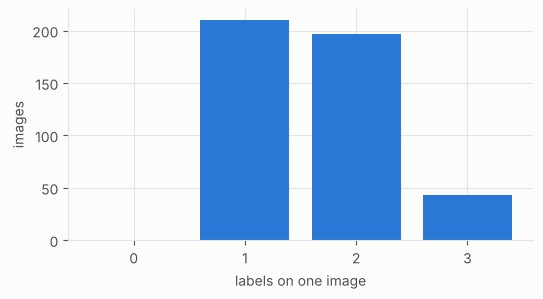

0 images have no label at all


In [4]:
per_image = Y.sum(1).astype(int)
fig, ax = plt.subplots(figsize=(6, 3))
vals = np.bincount(per_image)
ax.bar(range(len(vals)), vals, color=BLUE)
ax.set_xlabel("labels on one image"); ax.set_ylabel("images"); ax.set_xticks(range(len(vals)))
plt.show()
print(f"{int((per_image == 0).sum())} images have no label at all")

## Which labels appear together?
The diagonal is how often each label occurs; off-diagonal cells count images having both.

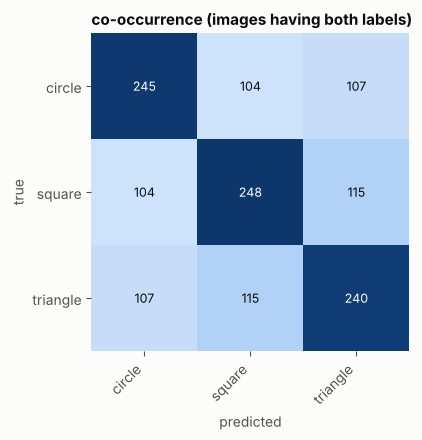

In [5]:
from cvkit.viz import plot_confusion_matrix

co = (Y.T @ Y).astype(int)
_ = plot_confusion_matrix(co, classes, title="co-occurrence (images having both labels)")

## Augmentation
Flips are safe for most tags; avoid anything that could *remove* a label from the picture (an aggressive crop can cut out the very thing you're tagging).

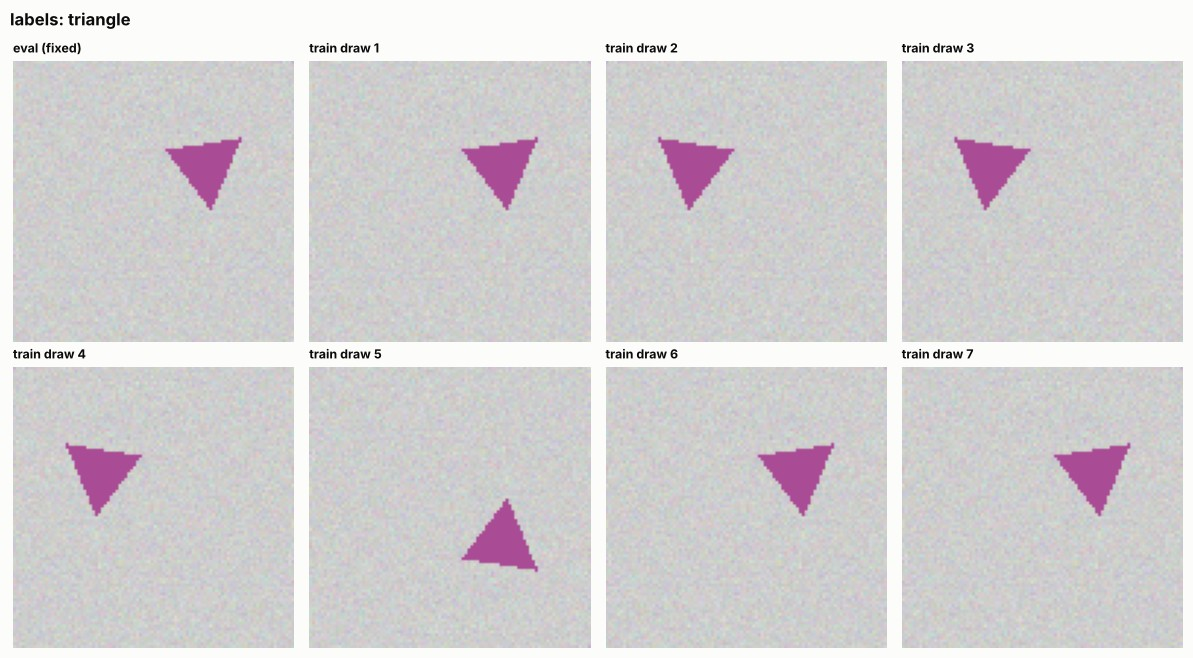

In [6]:
from PIL import Image
from cvkit.data import denormalize, image_transforms
from cvkit.viz import image_grid

size, aug = cfg["data"]["image_size"], cfg["data"]["augment"]
train_tf, eval_tf = image_transforms(size, aug, True), image_transforms(size, aug, False)
path, target = samples[0]
img = Image.open(path).convert("RGB")
shown = [denormalize(eval_tf(img))] + [denormalize(train_tf(img)) for _ in range(7)]
_ = image_grid(shown, ["eval (fixed)"] + [f"train draw {i}" for i in range(1, 8)], cols=4,
               suptitle="labels: " + (", ".join(c for c, v in zip(classes, target) if v) or "none"))

## What the model will actually receive
One batch from the training loader, exactly as `train()` gets it:

images: (16, 3, 96, 96) | labels: (16, 3) torch.float32 - one 0/1 per label per image


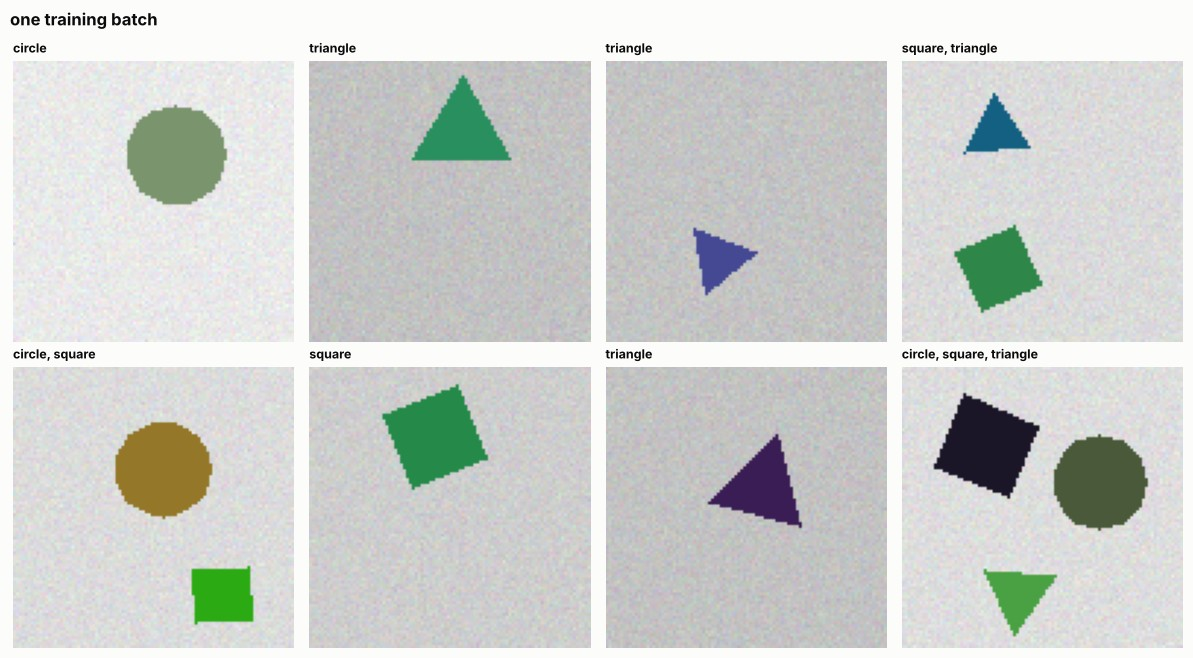

In [7]:
from cvkit.data import denormalize
from cvkit.viz import image_grid
from tasks.multilabel.data import build_loaders

loaders = build_loaders(cfg)
images, labels = next(iter(loaders["train"]))
print("images:", tuple(images.shape), "| labels:", tuple(labels.shape), labels.dtype, "- one 0/1 per label per image")
names = [", ".join(c for c, v in zip(loaders["classes"], l) if v) or "(none)" for l in labels[:8]]
_ = image_grid([denormalize(i) for i in images[:8]], names, cols=4, suptitle="one training batch")

## Before moving on
- [ ] Label names in the CSV header are what you intend
- [ ] No label is so rare the model can't learn it (or you set `train.pos_weight`)
- [ ] You looked at a few images and the 0/1 labels agree with what you see

Next: **[02_train_and_evaluate](02_train_and_evaluate.ipynb)**.